# Industry Project: Responsible-AI Review of an AI CV-Screening Feature (Production-Style)

> **Who is this notebook for?** Someone who has never taken part in a "responsible AI review" at a company.
> You do **not** need the formulas from the other notebooks in this folder. Every step is explained in plain English, and almost every line of code has a comment.
> Nothing here is legal advice: real reviews always involve your legal / compliance team.

---

### How this notebook is different from the others in `00_AI_Fundamentals/`

| Notebooks `01`-`06` in this folder | This notebook |
|---|---|
| Explain **one pillar at a time** (fairness, explainability, governance, privacy, robustness, ethics) | Runs **all of them together** as one review, the way a product team must before launch |
| Small NumPy examples with toy scores | A realistic (simulated) **hiring dataset** with missing values, proxies and historically biased labels |
| Fairness metrics computed once | A full **audit**: selection rates, impact ratios, TPR/FPR gaps, small-group warnings and bootstrap uncertainty |
| A mitigation shown in isolation | Several mitigations compared **honestly** (what each costs, what is legally allowed) |
| Model card printed as a dict | **Model card, risk register and launch checklist generated from code**, plus a monitoring plan tested on simulated production months |

Think of `01`-`06` as *learning each safety rule*; this notebook is *the safety inspection before the car goes on the road*.

---

### The business problem

You work at **TalentFlow**, a (fictional) HR software company. Product managers want to launch **"Smart Shortlist"**: an AI feature that reads job applications and **ranks candidates**, so recruiters at client companies interview the top **30%** first.

- Recruiters at a typical client receive ~2,000 applications per month and can interview only ~600 of them.
- The current approach is a **keyword filter** ("does the CV contain the words in the job ad?"). Recruiters say it misses good people.
- Hiring is a **high-stakes decision about people**. A biased shortlist can harm candidates, break anti-discrimination law and destroy the company's reputation (Amazon famously scrapped an internal CV-screening model after it learned to penalise CVs that mentioned "women's", as Reuters reported in October 2018).

**The launch is only allowed if a Responsible-AI Review Board signs off.** The board's criteria (our "policy"):

| Gate | Requirement |
|---|---|
| Usefulness | The model ranks candidates better than the keyword filter (higher ROC-AUC) |
| Selection fairness | **Impact ratio ≥ 0.80** for sex, age and sex × age groups (the US "four-fifths rule", also used in New York City's bias-audit law for hiring tools). A group **fails** when it is below 0.80 **and** the gap is statistically significant (US EEOC guidance looks at both) |
| Equal opportunity | Among candidates who historically succeeded, shortlist rates (TPR) may not differ by more than **10 percentage points** (again: fail = above the limit and significant) |
| Human oversight | The model **never rejects** anyone automatically; a recruiter makes every decision |
| Documentation | Model card, risk register, launch checklist and monitoring plan exist |

---

### The responsible-AI review workflow we will follow

```
 1. Intake & risk tier  ->  2. Stakeholders & harms  ->  3. Data review  ->  4. Baseline + model
                                                                                   |
 10. Monitoring plan  <-  9. Docs: model card, risk register, checklist  <-  5. Fairness audit
                                     ^                                             |
                         8. Human oversight design  <-  7. Mitigations  <-  6. Root-cause (proxies)
```

### Table of Contents
1. Setup: imports and the review policy
2. Use-case intake and risk classification (EU AI Act tiers)
3. Stakeholder and harm mapping
4. The data: historical applications (simulated)
5. Data review: representation and historical outcomes
6. Baseline and candidate model
7. Fairness audit
8. Root cause: finding proxy features
9. Mitigations and the honest trade-off
10. Final audit on the untouched test period
11. Human oversight: how the model is used
12. Documentation generated from code: model card, risk register, launch checklist
13. Monitoring plan, tested on simulated production months
14. Automated tests for the fairness tooling
15. Summary, exercises and resources

---
## 1. Setup: imports and the review policy

The review board's thresholds are **policy**, not code details, so they live in one frozen `dataclass`. If legal says "use 0.85 instead of 0.80", you change one line and re-run the whole review.

In [1]:
# ---- Standard library ----
import json                                  # save documentation artifacts as machine-readable files
import logging                               # timestamped status messages instead of print()
import tempfile                              # temporary folder: this notebook must not write into the repo
import warnings                              # hide noisy library warnings in a tutorial
from dataclasses import dataclass, asdict, field   # simple containers for config and records
from datetime import date                    # dates for the documents we generate
from pathlib import Path                     # modern file paths

# ---- Third-party ----
import matplotlib.pyplot as plt              # charts
import numpy as np                           # numbers and random generators
import pandas as pd                          # tables
import sklearn                               # we record its version in the model card
from sklearn.base import clone               # fresh, unfitted copies of a pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression   # simple, explainable model (important for audits)
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import norm                 # normal distribution, for a simple significance test

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("rai_review")

# A consistent, colour-blind-friendly palette for every chart in this notebook
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "grey": "#8a8984", "red": "#e34948"}


@dataclass(frozen=True)
class ReviewPolicy:
    """Thresholds agreed by the Responsible-AI Review Board (one place to change them)."""
    random_state: int = 42
    shortlist_rate: float = 0.30          # recruiters interview the top 30% of applicants
    min_impact_ratio: float = 0.80        # four-fifths rule: each group's selection rate >= 80% of the best group's
    max_tpr_gap: float = 0.10             # equal-opportunity gap allowed (10 percentage points)
    min_group_size: int = 100             # below this, a group's metrics are too noisy to pass/fail on
    significance_level: float = 0.05      # a gap only FAILS if it is also statistically significant
    protected_attributes: tuple = ("sex", "age_band")   # audited, but NEVER used as model inputs
    target: str = "advanced_to_offer"     # historical outcome: did a recruiter move this person to an offer?


POLICY = ReviewPolicy()
log.info("scikit-learn %s | policy: %s", sklearn.__version__, asdict(POLICY))

2026-10-21 18:00:12,081 | INFO | scikit-learn 1.9.0 | policy: {'random_state': 42, 'shortlist_rate': 0.3, 'min_impact_ratio': 0.8, 'max_tpr_gap': 0.1, 'min_group_size': 100, 'significance_level': 0.05, 'protected_attributes': ('sex', 'age_band'), 'target': 'advanced_to_offer'}


---
## 2. Use-case intake and risk classification (EU AI Act tiers)

Every responsible-AI process starts with an **intake form**: *what does the feature do, who is affected, and how risky is it?* The answer decides how much review is needed. A spell-checker needs almost none; a hiring tool needs a lot.

The **EU AI Act** (Regulation (EU) 2024/1689) is the best-known risk framework. Simplified:

| Tier | Examples | What it means |
|---|---|---|
| **Prohibited** (Art. 5) | social scoring, **emotion recognition at work or school**, manipulative AI | You may not sell or use it in the EU |
| **High risk** (Art. 6 + Annex III) | **recruitment and selection of candidates**, credit scoring, exam grading, medical devices | Allowed, with strict duties: risk management, data governance, documentation, logging, human oversight, accuracy, monitoring |
| **Limited risk** (Art. 50) | chatbots, AI-generated images | Transparency: tell people they are dealing with AI |
| **Minimal risk** | spam filters, spell-checkers | No special duties |

Two details trip people up:
- **Art. 6(3) exception:** an Annex III system is *not* high-risk if it only does a narrow procedural or preparatory task (e.g. de-duplicating CVs), **unless it profiles people**. Ranking candidates is profiling, so Smart Shortlist stays high-risk.
- **Timing:** prohibitions apply since February 2025. The high-risk duties for Annex III systems were scheduled for August 2026, and a 2026 amendment (the "Digital Omnibus") moved them to December 2027. Dates change, so companies keep the classification logic in code and the dates in a config that legal reviews.

In the US there is no single AI law, but hiring tools fall under anti-discrimination law (EEOC "four-fifths" guideline) and, in New York City, **Local Law 144** requires an annual independent **bias audit** of automated hiring tools with published impact ratios.

Below, the intake rules become a small, testable function. `03_accountability_and_governance.ipynb` has a 10-line version; here we add the exception rule, the reasons and the resulting obligations, because a reviewer must be able to see **why** a tier was chosen.

In [2]:
@dataclass
class AIUseCase:
    """The intake form a product team fills in before building an AI feature."""
    name: str
    description: str
    area: str                                # e.g. "employment", "customer_support", "internal_tools"
    profiles_people: bool = False            # does it score/rank/evaluate individuals?
    narrow_procedural_task: bool = False     # e.g. de-duplicating, formatting; no judgement about a person
    interacts_with_people: bool = False      # e.g. chatbot
    emotion_recognition: bool = False
    generates_content: bool = False


PROHIBITED_RULES = {   # simplified subset of Art. 5
    "emotion_recognition_at_work": lambda u: u.emotion_recognition and u.area in {"employment", "education"},
}
ANNEX_III_AREAS = {"biometrics", "critical_infrastructure", "education", "employment",
                   "essential_services", "law_enforcement", "migration", "justice"}
HIGH_RISK_OBLIGATIONS = [
    "Risk-management system (Art. 9)", "Data governance & bias examination (Art. 10)",
    "Technical documentation (Art. 11)", "Automatic event logging (Art. 12)",
    "Instructions & transparency for the deploying client (Art. 13)", "Human oversight (Art. 14)",
    "Accuracy, robustness, cybersecurity (Art. 15)", "Post-market monitoring (Art. 72)",
]


def classify_risk(use_case: AIUseCase) -> dict:
    """Return the (simplified) EU AI Act tier, the reason, and the obligations. Not legal advice."""
    for rule_name, rule in PROHIBITED_RULES.items():
        if rule(use_case):
            return {"tier": "PROHIBITED", "reason": rule_name, "obligations": ["Do not build/deploy in the EU"]}
    if use_case.area in ANNEX_III_AREAS:
        if use_case.narrow_procedural_task and not use_case.profiles_people:
            return {"tier": "NOT HIGH-RISK (Art. 6(3) exception)",
                    "reason": f"Annex III area '{use_case.area}' but only a narrow procedural task",
                    "obligations": ["Document the exception assessment", "Register the system"]}
        return {"tier": "HIGH RISK", "reason": f"Annex III area '{use_case.area}'"
                + (" + profiling of people" if use_case.profiles_people else ""),
                "obligations": HIGH_RISK_OBLIGATIONS}
    if use_case.interacts_with_people or use_case.generates_content:
        return {"tier": "LIMITED RISK", "reason": "interacts with people / generates content",
                "obligations": ["Tell users they are interacting with AI / label AI content (Art. 50)"]}
    return {"tier": "MINIMAL RISK", "reason": "no listed risk factor", "obligations": ["Voluntary codes of conduct"]}


portfolio = [
    AIUseCase("Smart Shortlist", "Rank job applicants for recruiters", "employment", profiles_people=True),
    AIUseCase("Candidate FAQ bot", "Answer applicants' questions about the process", "customer_support",
              interacts_with_people=True),
    AIUseCase("Interview mood meter", "Detect candidate emotions in video interviews", "employment",
              emotion_recognition=True, profiles_people=True),
    AIUseCase("CV de-duplicator", "Merge duplicate CV uploads of the same person", "employment",
              narrow_procedural_task=True),
    AIUseCase("Job-ad spell checker", "Fix typos in job adverts", "internal_tools"),
]
intake = pd.DataFrame([{"use_case": u.name, **{k: v for k, v in classify_risk(u).items() if k != "obligations"},
                        "n_obligations": len(classify_risk(u)["obligations"])} for u in portfolio])
intake

,use_case,tier,reason,n_obligations
0,Smart Shortlist,HIGH RISK,Annex III area 'employment' + profiling of people,8
1,Candidate FAQ bot,LIMITED RISK,interacts with people / generates content,1
2,Interview mood meter,PROHIBITED,emotion_recognition_at_work,1
3,CV de-duplicator,NOT HIGH-RISK (Art. 6(3) exception),Annex III area 'employment' but only a narrow ...,2
4,Job-ad spell checker,MINIMAL RISK,no listed risk factor,1


In [3]:
# The tier decides the review depth. Smart Shortlist is high-risk, so print its full obligation list.
shortlist_risk = classify_risk(portfolio[0])
print(f"Smart Shortlist -> {shortlist_risk['tier']} ({shortlist_risk['reason']})\nObligations:")
for item in shortlist_risk["obligations"]:
    print("  [ ]", item)

Smart Shortlist -> HIGH RISK (Annex III area 'employment' + profiling of people)
Obligations:
  [ ] Risk-management system (Art. 9)
  [ ] Data governance & bias examination (Art. 10)
  [ ] Technical documentation (Art. 11)
  [ ] Automatic event logging (Art. 12)
  [ ] Instructions & transparency for the deploying client (Art. 13)
  [ ] Human oversight (Art. 14)
  [ ] Accuracy, robustness, cybersecurity (Art. 15)
  [ ] Post-market monitoring (Art. 72)


Notice that the **"Interview mood meter"** idea is stopped at intake: emotion recognition in the workplace is prohibited in the EU. Killing a bad idea before anyone writes model code is the cheapest win a review process can deliver.

---
## 3. Stakeholder and harm mapping

Next the team lists **everyone affected** and **what could go wrong for them**. Each harm gets a **severity** (1 = minor, 5 = life-changing) and a **likelihood** (1 = rare, 5 = expected). Their product is a simple **risk score** that tells the board where to look first. This is the "Map" step of the NIST AI Risk Management Framework.

Tip from practice: invite people who are *not* engineers (recruiters, HR, legal, a candidate panel). They spot harms engineers miss.

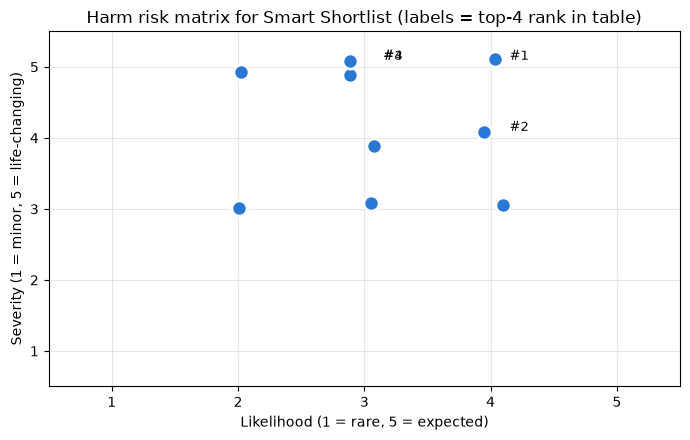

,stakeholder,harm,severity,likelihood,risk_score,priority
0,Applicants (women),Ranked lower because of career breaks (proxy d...,5,4,20,high
1,Recruiters,Over-trust: rubber-stamping the AI ranking (au...,4,4,16,high
2,Applicants (40+),Ranked lower because of age-related signals,5,3,15,high
3,Client companies,Legal liability for discriminatory hiring,5,3,15,high
4,Applicants (all),Rejected without explanation or a way to contest,4,3,12,medium
5,Undisclosed-sex group,Too few people to measure fairness reliably,3,4,12,medium
6,TalentFlow,Reputation damage / regulator fines,5,2,10,medium
7,Client companies,Good candidates missed (worse hires),3,3,9,medium
8,Applicants (all),Personal data used beyond the job application,3,2,6,low


In [4]:
harms = pd.DataFrame([
    # stakeholder,          harm,                                                        severity, likelihood
    ("Applicants (women)",   "Ranked lower because of career breaks (proxy discrimination)", 5, 4),
    ("Applicants (40+)",     "Ranked lower because of age-related signals",                  5, 3),
    ("Applicants (all)",     "Rejected without explanation or a way to contest",             4, 3),
    ("Applicants (all)",     "Personal data used beyond the job application",               3, 2),
    ("Recruiters",           "Over-trust: rubber-stamping the AI ranking (automation bias)", 4, 4),
    ("Client companies",     "Legal liability for discriminatory hiring",                    5, 3),
    ("Client companies",     "Good candidates missed (worse hires)",                         3, 3),
    ("TalentFlow",           "Reputation damage / regulator fines",                          5, 2),
    ("Undisclosed-sex group", "Too few people to measure fairness reliably",                 3, 4),
], columns=["stakeholder", "harm", "severity", "likelihood"])
harms["risk_score"] = harms["severity"] * harms["likelihood"]       # 1..25
harms["priority"] = pd.cut(harms["risk_score"], [0, 6, 12, 25], labels=["low", "medium", "high"])
harms = harms.sort_values("risk_score", ascending=False).reset_index(drop=True)

# Risk matrix chart: where each harm sits (jitter only to avoid overlapping dots)
rng_plot = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(harms["likelihood"] + rng_plot.uniform(-0.12, 0.12, len(harms)),
           harms["severity"] + rng_plot.uniform(-0.12, 0.12, len(harms)),
           s=120, color=COLORS["blue"], edgecolor="white", linewidth=2, zorder=3)
for i, row in harms.head(4).iterrows():                       # label only the top risks (selective labels)
    ax.annotate(f"#{i + 1}", (row["likelihood"] + 0.15, row["severity"] + 0.1), fontsize=9)
ax.set_xlim(0.5, 5.5); ax.set_ylim(0.5, 5.5)
ax.set_xlabel("Likelihood (1 = rare, 5 = expected)"); ax.set_ylabel("Severity (1 = minor, 5 = life-changing)")
ax.set_title("Harm risk matrix for Smart Shortlist (labels = top-4 rank in table)")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
harms

The top harms tell us **what the fairness audit must test**: proxy discrimination by sex (career breaks) and by age, recruiter over-trust, and the small undisclosed group. Each will reappear in the risk register in Section 12.

---
## 4. The data: historical applications (simulated)

In a real company this would be an export from the applicant-tracking system (ATS), e.g. `SELECT ... FROM applications JOIN outcomes ...`. So that the notebook runs anywhere, we **simulate** 16,000 applications from 2023-2025 that behave like real ones, including the problems a review must find:

- **Talent is equally distributed**: the hidden true ability of candidates does not depend on sex or age.
- **Historical labels are biased**: past recruiters were less likely to move women, people with career gaps, and people over 40 to an offer. A model trained on these labels can learn the bias.
- **Proxies**: women more often have an **employment gap** (e.g. parental leave), and men more often have an internal **referral**. Neither column says "sex", but both carry information about it.
- **Mess**: some applicants skipped the online assessment (missing values), and ~3% did not disclose their sex.

Because this is a simulation we also keep a column `truly_qualified` (the hidden truth). **In real life you never have this column**; we use it only to show what biased labels hide.

In [5]:
def make_applications(n: int = 16000, seed: int = 42, start: str = "2023-01-01", end: str = "2025-12-31",
                      skip_test_rate_40plus: float = 0.15) -> pd.DataFrame:
    """Simulate an applicant-tracking-system export with realistic (and biased) history."""
    rng = np.random.default_rng(seed)
    sex = rng.choice(["Female", "Male", "Undisclosed"], n, p=[0.44, 0.53, 0.03])
    age_band = rng.choice(["Under 40", "40 and over"], n, p=[0.68, 0.32])
    older, female, male = age_band == "40 and over", sex == "Female", sex == "Male"

    ability = rng.normal(0, 1, n)                                   # hidden true ability: SAME for all groups
    years_exp = np.where(older, rng.normal(17, 5, n), rng.gamma(2.2, 2.3, n)).clip(0, 40).round(1)
    has_gap = rng.random(n) < np.where(female, 0.45, 0.12) + 0.08 * older      # career breaks (proxy for sex)
    gap_months = np.where(has_gap, rng.gamma(2, 6, n).round() + 1, 0)
    skills_match = (55 + 8 * ability + 0.8 * np.minimum(years_exp, 15) + rng.normal(0, 13, n)).clip(0, 100).round()
    assessment = (62 + 10 * ability + rng.normal(0, 8, n)).clip(0, 100).round()   # online test: the best signal
    skipped = rng.random(n) < np.where(older, skip_test_rate_40plus, 0.08)        # some never took the test
    assessment = np.where(skipped, np.nan, assessment)
    education = np.where(ability + rng.normal(0, 1.2, n) > 0.8, "Master",
                         np.where(rng.random(n) < 0.75, "Bachelor", "No degree"))
    referral = (rng.random(n) < np.where(male, 0.20, 0.11)).astype(int)        # referrals mirror today's workforce
    job_changes = rng.poisson(0.8 + 0.12 * np.minimum(years_exp, 20))

    truly_qualified = (ability + 0.02 * np.minimum(years_exp, 12) + rng.normal(0, 0.35, n)) > 0.65
    # Historical decision by past recruiters: driven by ability, BUT also by bias against gaps, age and women
    logit = (-1.9 + 1.5 * ability + 0.07 * np.minimum(years_exp, 12) + 0.6 * referral
             - 0.08 * np.clip(gap_months, 0, 24) - 0.55 * older - 0.35 * female)
    advanced = rng.binomial(1, 1 / (1 + np.exp(-logit)))

    days = (pd.Timestamp(end) - pd.Timestamp(start)).days
    applied_at = pd.Timestamp(start) + pd.to_timedelta(rng.integers(0, days, n), unit="D")
    df = pd.DataFrame({
        "application_id": [f"A{seed:03d}-{i:05d}" for i in range(n)], "applied_at": applied_at,
        "sex": sex, "age_band": age_band, "years_experience": years_exp, "employment_gap_months": gap_months,
        "skills_match": skills_match, "assessment_score": assessment, "education": education,
        "referral": referral, "job_changes": job_changes,
        "advanced_to_offer": advanced, "truly_qualified": truly_qualified.astype(int),
    })
    return df.sort_values("applied_at").reset_index(drop=True)


apps = make_applications()
print(f"{len(apps):,} applications from {apps['applied_at'].min():%Y-%m-%d} to {apps['applied_at'].max():%Y-%m-%d}")
apps.head()

16,000 applications from 2023-01-01 to 2025-12-30


,application_id,applied_at,sex,age_band,years_experience,employment_gap_months,skills_match,assessment_score,education,referral,job_changes,advanced_to_offer,truly_qualified
0,A042-00483,2023-01-01,Female,Under 40,1.5,0.0,41.0,54.0,Bachelor,0,0,0,0
1,A042-06324,2023-01-01,Male,Under 40,3.0,0.0,58.0,63.0,Bachelor,0,0,0,0
2,A042-04503,2023-01-01,Male,40 and over,15.6,22.0,65.0,43.0,No degree,0,1,0,0
3,A042-02630,2023-01-01,Female,Under 40,11.8,0.0,45.0,NaN,No degree,1,0,0,0
4,A042-15785,2023-01-01,Female,Under 40,1.1,0.0,53.0,72.0,Bachelor,0,1,0,0


---
## 5. Data review: representation and historical outcomes

EU AI Act Art. 10 asks providers to examine training data **for possible biases**. In practice the first check is a simple table per group: *how many people, how much missing data, and what happened to them historically?*

In [6]:
def group_profile(df: pd.DataFrame, by: str) -> pd.DataFrame:
    """Representation and outcome summary for one protected attribute."""
    g = df.groupby(by)
    return pd.DataFrame({
        "applicants": g.size(),
        "share_%": (g.size() / len(df) * 100).round(1),
        "assessment_missing_%": (g["assessment_score"].apply(lambda s: s.isna().mean()) * 100).round(1),
        "has_gap_%": (g["employment_gap_months"].apply(lambda s: (s > 0).mean()) * 100).round(1),
        "referral_%": (g["referral"].mean() * 100).round(1),
        "historical_offer_rate_%": (g[POLICY.target].mean() * 100).round(1),
        "truly_qualified_%  (hidden)": (g["truly_qualified"].mean() * 100).round(1),
    })


for attribute in POLICY.protected_attributes:
    print(f"\n=== {attribute} ===")
    print(group_profile(apps, attribute).to_string())


=== sex ===
             applicants  share_%  assessment_missing_%  has_gap_%  referral_%  historical_offer_rate_%  truly_qualified_%  (hidden)
sex                                                                                                                                
Female             7083     44.3                  10.4       47.0        11.2                     16.6                         31.1
Male               8447     52.8                  10.2       14.6        20.1                     24.6                         31.1
Undisclosed         470      2.9                  10.4       14.9        10.9                     24.3                         31.5

=== age_band ===
             applicants  share_%  assessment_missing_%  has_gap_%  referral_%  historical_offer_rate_%  truly_qualified_%  (hidden)
age_band                                                                                                                           
40 and over        5224     32.6             

**What the review board reads from this table:**
- Women had a **lower historical offer rate** than men, although (in the hidden truth) they are equally often qualified. That is **historical bias in the labels**: a model trained to imitate past decisions can learn it.
- Women have career gaps far more often, and men get referrals more often: two candidate **proxy features**.
- 40+ applicants skip the online test more often, so their assessment score is missing more often. Missing data that is unequal across groups is itself a fairness risk.
- The "Undisclosed" group is small (~3%), so its metrics will be noisy.

### Honest split by time
We train on 2023-2024, choose mitigations on the first half of 2025 (**validation**), and keep the second half of 2025 as an untouched **test** period, exactly like a model that is trained on the past and used on the future.

In [7]:
FEATURES_NUM = ["years_experience", "employment_gap_months", "skills_match", "assessment_score",
                "referral", "job_changes"]
FEATURES_CAT = ["education"]
# Protected attributes and the hidden truth are deliberately NOT in the feature lists.

train = apps[apps["applied_at"] < "2025-01-01"]
valid = apps[(apps["applied_at"] >= "2025-01-01") & (apps["applied_at"] < "2025-07-01")]
test = apps[apps["applied_at"] >= "2025-07-01"]
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:5s}: {len(part):5,} rows | {part['applied_at'].min():%Y-%m} to {part['applied_at'].max():%Y-%m}"
          f" | historical offer rate {part[POLICY.target].mean():.1%}")

train: 10,696 rows | 2023-01 to 2024-12 | historical offer rate 21.1%
valid: 2,650 rows | 2025-01 to 2025-06 | historical offer rate 20.5%
test : 2,654 rows | 2025-07 to 2025-12 | historical offer rate 21.2%


---
## 6. Baseline and candidate model

**Baseline first:** the board compares the AI against what recruiters use today, the keyword filter (`skills_match`). If the model is not clearly better, there is no reason to take on the extra risk.

**Model choice:** for a high-risk decision about people, teams usually start with an **interpretable** model (logistic regression). Its weights can be read and challenged by the board, which is much harder for a large boosted ensemble. Protected attributes are **not** given to the model.

**From score to shortlist:** recruiters interview the top 30%, so the cut-off is the 70th percentile of scores on validation data.

In [8]:
def make_model(numeric_features: list[str]) -> Pipeline:
    """Impute + scale numbers, one-hot encode education, then logistic regression."""
    preprocess = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
         numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEATURES_CAT),
    ])
    return Pipeline([("preprocess", preprocess), ("model", LogisticRegression(max_iter=1000))])


def shortlist_threshold(scores: np.ndarray, rate: float = POLICY.shortlist_rate) -> float:
    """Score cut-off so that `rate` of applicants are shortlisted."""
    return float(np.quantile(scores, 1 - rate))


# Baseline: the keyword filter used today
baseline_scores = valid["skills_match"].to_numpy()

# Candidate: logistic regression trained on historical decisions
candidate = make_model(FEATURES_NUM).fit(train, train[POLICY.target])
candidate_scores = candidate.predict_proba(valid)[:, 1]

usefulness = pd.DataFrame({
    "AUC vs historical decisions": [roc_auc_score(valid[POLICY.target], s) for s in (baseline_scores, candidate_scores)],
    "AUC vs true qualification (hidden)": [roc_auc_score(valid["truly_qualified"], s)
                                           for s in (baseline_scores, candidate_scores)],
}, index=["Keyword filter (today)", "Logistic regression"]).round(3)
usefulness

,AUC vs historical decisions,AUC vs true qualification (hidden)
Keyword filter (today),0.651,0.736
Logistic regression,0.792,0.843


The model passes the **usefulness gate**: it ranks candidates clearly better than the keyword filter, on both the historical labels and the hidden truth. Now the important question: *is it fair?*

---
## 7. Fairness audit

For each group we compute the numbers hiring regulators and auditors actually use:

| Metric | Plain English | Rule of thumb |
|---|---|---|
| **Selection rate** | share of the group that gets shortlisted | - |
| **Impact ratio** | group's selection rate ÷ selection rate of the most-selected group | ≥ 0.80 (four-fifths rule; NYC LL144 reports exactly this) |
| **TPR** (true positive rate) | among people who historically got an offer, the share we shortlist | gap ≤ 0.10 (equal opportunity) |
| **FPR** (false positive rate) | among people who historically did *not* get an offer, the share we shortlist | gap reported |

Libraries such as **Fairlearn** (`MetricFrame`) or **AIF360** compute these for you; we write the function by hand (20 lines) so every number is transparent. Each group gets one of four statuses:

- **pass**: impact ratio ≥ 0.80;
- **FAIL**: impact ratio < 0.80 **and** a two-proportion z-test says the gap to the best group is unlikely to be chance (p < 0.05);
- **warn**: below 0.80 but not significant (often a small group): investigate and keep monitoring;
- **too small**: fewer than `min_group_size` people; numbers are reported (laws like LL144 require the counts) but not judged.

We also audit the **intersection** sex × age (e.g. *women under 40*). NYC LL144 requires it, because a model can look fine on sex and on age separately and still disadvantage a combination.

In [9]:
def two_proportion_p_value(k1: int, n1: int, k2: int, n2: int) -> float:
    """Two-sided z-test: is rate k1/n1 different from k2/n2 by more than chance?"""
    pooled = (k1 + k2) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    return 1.0 if se == 0 else float(2 * norm.sf(abs(k1 / n1 - k2 / n2) / se))


def fairness_table(df: pd.DataFrame, selected: np.ndarray, attribute: str,
                   policy: ReviewPolicy = POLICY) -> pd.DataFrame:
    """Per-group selection rate, impact ratio, TPR and FPR (labels = historical outcome),
    with a significance test against the most-selected group."""
    data = df.assign(selected=np.asarray(selected).astype(bool))
    rows = []
    for group, part in data.groupby(attribute):
        positives = part[part[policy.target] == 1]
        negatives = part[part[policy.target] == 0]
        rows.append({"group": group, "n": len(part), "n_selected": int(part["selected"].sum()),
                     "selection_rate": part["selected"].mean(),
                     "n_positives": len(positives), "n_tp": int(positives["selected"].sum()),
                     "TPR": positives["selected"].mean() if len(positives) else np.nan,
                     "FPR": negatives["selected"].mean() if len(negatives) else np.nan})
    table = pd.DataFrame(rows).set_index("group")
    reliable = table["n"] >= policy.min_group_size
    best = table.loc[reliable, "selection_rate"].idxmax()            # most-selected reliable group
    table["impact_ratio"] = table["selection_rate"] / table.loc[best, "selection_rate"]
    table["p_value_vs_best"] = [two_proportion_p_value(r.n_selected, r.n, table.loc[best, "n_selected"],
                                                       table.loc[best, "n"]) for r in table.itertuples()]
    below = table["impact_ratio"] < policy.min_impact_ratio
    significant = table["p_value_vs_best"] < policy.significance_level
    table["status"] = np.select([~reliable, ~below, below & significant],
                                ["too small: monitor", "pass", "FAIL"], default="warn: <0.8, not significant")
    return table.drop(columns=["n_selected", "n_positives", "n_tp"]).assign(
        _tp=table["n_tp"], _pos=table["n_positives"])          # keep counts (hidden columns) for TPR tests


def with_intersection(df: pd.DataFrame) -> pd.DataFrame:
    """Add the intersectional category (e.g. 'Female / Under 40'), required by NYC LL144 bias audits."""
    return df.assign(sex_x_age=df["sex"] + " / " + df["age_band"])


def audit_summary(df: pd.DataFrame, selected: np.ndarray, policy: ReviewPolicy = POLICY) -> dict:
    """Headline numbers per model, for sex, age band and the sex x age intersection:
    worst impact ratio, number of significant FAILs, and the TPR gap (with its significance)."""
    df = with_intersection(df)
    summary, n_fail, tpr_fail = {}, 0, False
    for attribute in policy.protected_attributes + ("sex_x_age",):
        t = fairness_table(df, selected, attribute, policy)
        n_fail += int((t["status"] == "FAIL").sum())
        t = t[t["n"] >= policy.min_group_size]
        summary[f"min_impact_ratio_{attribute}"] = t["impact_ratio"].min()
        if attribute != "sex_x_age":                     # TPR gaps on small intersections are too noisy to gate
            hi, lo = t["TPR"].idxmax(), t["TPR"].idxmin()
            gap = t.loc[hi, "TPR"] - t.loc[lo, "TPR"]
            p = two_proportion_p_value(t.loc[hi, "_tp"], t.loc[hi, "_pos"], t.loc[lo, "_tp"], t.loc[lo, "_pos"])
            summary[f"tpr_gap_{attribute}"] = gap
            tpr_fail |= bool(gap > policy.max_tpr_gap and p < policy.significance_level)
    summary["significant_IR_fails"] = n_fail
    summary["significant_TPR_gap"] = tpr_fail
    return summary


def show(table: pd.DataFrame) -> pd.DataFrame:
    """Hide the helper count columns when printing."""
    return table.drop(columns=["_tp", "_pos"]).round(3)


candidate_selected = candidate_scores >= shortlist_threshold(candidate_scores)
for attribute in POLICY.protected_attributes + ("sex_x_age",):
    print(f"\n=== Candidate model, validation, by {attribute} ===")
    print(show(fairness_table(with_intersection(valid), candidate_selected, attribute)).to_string())


=== Candidate model, validation, by sex ===
                n  selection_rate    TPR    FPR  impact_ratio  p_value_vs_best              status
group                                                                                             
Female       1195           0.251  0.620  0.180         0.733            0.000                FAIL
Male         1373           0.342  0.631  0.250         1.000            1.000                pass
Undisclosed    82           0.305  0.750  0.161         0.891            0.487  too small: monitor

=== Candidate model, validation, by age_band ===
                n  selection_rate    TPR    FPR  impact_ratio  p_value_vs_best status
group                                                                                
40 and over   871           0.305  0.618  0.225         1.000            1.000   pass
Under 40     1779           0.297  0.638  0.209         0.974            0.671   pass

=== Candidate model, validation, by sex_x_age ===
               

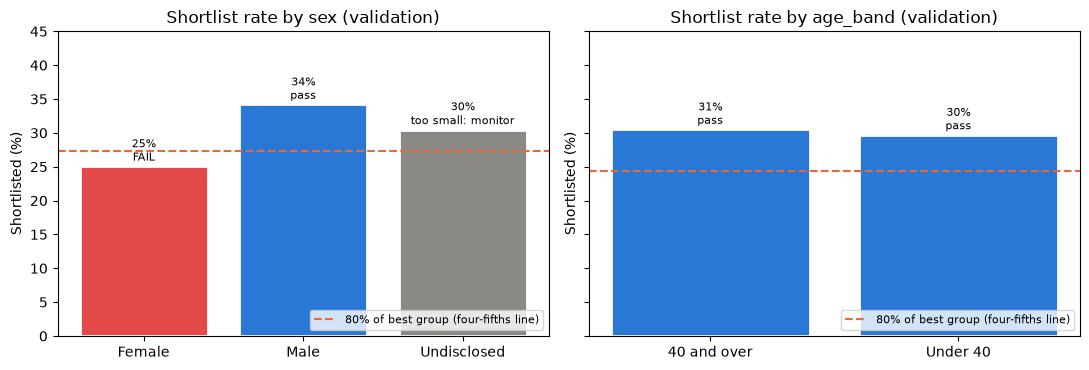

In [10]:
# Visual version for the review board: selection rate per group vs. the four-fifths line
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, attribute in zip(axes, POLICY.protected_attributes):
    t = fairness_table(valid, candidate_selected, attribute)
    colors = [COLORS["grey"] if s.startswith("too small") else COLORS["red"] if s == "FAIL" else COLORS["blue"]
              for s in t["status"]]
    ax.bar(t.index, t["selection_rate"] * 100, color=colors, edgecolor="white", linewidth=2)
    reference = t.loc[t["n"] >= POLICY.min_group_size, "selection_rate"].max()
    ax.axhline(reference * POLICY.min_impact_ratio * 100, color=COLORS["orange"], ls="--",
               label="80% of best group (four-fifths line)")
    for x, (rate, status) in enumerate(zip(t["selection_rate"], t["status"])):
        ax.text(x, rate * 100 + 0.8, f"{rate:.0%}\n{status}", ha="center", fontsize=8)
    ax.set_title(f"Shortlist rate by {attribute} (validation)"); ax.set_ylim(0, 45)
    ax.set_ylabel("Shortlisted (%)"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Reading the audit:** the candidate model **fails the four-fifths rule for women** (impact ratio about 0.73, p < 0.001) even though sex was never an input, and both female intersections fail too. By age band alone it passes. The "Undisclosed" group is too small to pass or fail; the board will require monitoring for it instead.

### How sure are we? Bootstrap the impact ratio
A validation half-year has only a few hundred women. Is the failure real or bad luck? A quick **bootstrap** (resample the applicants with replacement 1,000 times and recompute) gives an uncertainty range.

In [11]:
def bootstrap_impact_ratio(df: pd.DataFrame, selected: np.ndarray, attribute: str, group: str,
                           reference: str, n_boot: int = 1000, seed: int = POLICY.random_state) -> tuple:
    """95% bootstrap interval for selection_rate(group) / selection_rate(reference)."""
    rng = np.random.default_rng(seed)
    is_group = (df[attribute] == group).to_numpy()
    is_ref = (df[attribute] == reference).to_numpy()
    sel = np.asarray(selected, dtype=float)
    idx = rng.integers(0, len(df), size=(n_boot, len(df)))          # n_boot resamples of row indices
    ratios = ((sel[idx] * is_group[idx]).sum(1) / is_group[idx].sum(1)) / \
             ((sel[idx] * is_ref[idx]).sum(1) / is_ref[idx].sum(1))
    return tuple(np.percentile(ratios, [2.5, 50, 97.5]))


low, mid, high = bootstrap_impact_ratio(valid, candidate_selected, "sex", "Female", "Male")
print(f"Impact ratio Female/Male: median {mid:.2f}, 95% interval [{low:.2f}, {high:.2f}]")
if high < POLICY.min_impact_ratio:
    print("Whole interval below 0.80 -> a real problem, not noise")
elif mid < POLICY.min_impact_ratio:
    print("Most of the interval is below 0.80 -> very likely a real problem (the z-test above agrees)")
else:
    print("Interval mostly above 0.80 -> may be noise; keep monitoring")

Impact ratio Female/Male: median 0.73, 95% interval [0.65, 0.83]
Most of the interval is below 0.80 -> very likely a real problem (the z-test above agrees)


### What the historical labels hide
TPR above is measured against **past recruiter decisions**, which were themselves biased. Because our data is simulated we can peek at the hidden truth: *among truly qualified people, how many does each approach shortlist?* In a real review you cannot do this, which is why teams also commission **structured re-reviews** of a sample of CVs by trained, blinded reviewers to estimate it.

In [12]:
def qualified_shortlist_rate(df, selected, attribute="sex"):
    """Share of TRULY qualified people shortlisted per group (only possible with simulated data)."""
    d = df.assign(selected=np.asarray(selected))
    return d[d["truly_qualified"] == 1].groupby(attribute)["selected"].mean().round(3)


print(pd.DataFrame({"keyword filter": qualified_shortlist_rate(valid, baseline_scores >= shortlist_threshold(baseline_scores)),
                    "candidate model": qualified_shortlist_rate(valid, candidate_selected)}))

             keyword filter  candidate model
sex                                         
Female                0.527            0.540
Male                  0.533            0.719
Undisclosed           0.536            0.750


Qualified women are shortlisted clearly less often than qualified men by the candidate model (about 54% vs 72%): the bias in the labels has flowed into the model. The keyword filter treats the sexes similarly but is less accurate for everyone (about 53% of qualified people shortlisted).

---
## 8. Root cause: finding proxy features

The model never saw `sex`, so how did it discriminate? Two standard checks:
1. **Can the features predict the protected attribute?** If a simple model can guess sex from the features, the features contain proxies.
2. **What did the model learn?** Logistic-regression weights show which inputs push the score down.

In [13]:
# Check 1: how well does each single feature "leak" sex? (AUC 0.5 = no information, 1.0 = perfect proxy)
binary = apps[apps["sex"].isin(["Female", "Male"])]
is_female = (binary["sex"] == "Female").astype(int)
leakage = {col: abs(roc_auc_score(is_female, binary[col].fillna(binary[col].median())) - 0.5) + 0.5
           for col in FEATURES_NUM}
proxy_check = pd.Series(leakage, name="AUC for predicting sex").sort_values(ascending=False).round(3)

# Check 2: the model's standardized weights (positive = raises the shortlist score)
weights = pd.Series(candidate.named_steps["model"].coef_[0][:len(FEATURES_NUM)], index=FEATURES_NUM,
                    name="model weight").round(3)
pd.concat([proxy_check, weights], axis=1).sort_values("AUC for predicting sex", ascending=False)

,AUC for predicting sex,model weight
employment_gap_months,0.661,-0.536
referral,0.544,0.201
years_experience,0.507,-0.030
job_changes,0.506,0.036
assessment_score,0.503,0.733
skills_match,0.502,0.326


`employment_gap_months` is both the **strongest proxy for sex** and has a clearly **negative weight**: the model learned "career gaps are bad" from past recruiters, and because women have gaps more often, women are ranked lower. `referral` is a weaker proxy that pushes in the same direction. This is textbook **proxy discrimination**, exactly the "career break" harm the stakeholder map flagged as the #1 risk.

---
## 9. Mitigations and the honest trade-off

The board asks the team to compare options. Fairness fixes come in three families (see `01_bias_and_fairness.ipynb`):

| Option | Family | Idea |
|---|---|---|
| A. Remove the gap feature | pre-processing / feature policy | Do not let the model use career gaps at all (also a legitimate **job-relatedness** question: is a gap evidence of lower skill? usually not) |
| B. Reweighing (Kamiran & Calders) | pre-processing | Give each (group, label) combination a weight so that group and label look independent in training |
| C. Per-group thresholds | post-processing | Use a lower cut-off for the disadvantaged group so selection rates match |
| D. Remove gap **and** referral | feature policy | Remove both proxies |

> ⚠️ **Policy check before maths:** option C uses sex **at decision time**. In US employment law, adjusting scores or cut-offs by sex or race is prohibited (Civil Rights Act 1991, §106, the "race-norming" ban), and in the EU it is direct differential treatment. The board therefore marks it **not allowed** for hiring, even if its numbers look perfect. (In other domains, e.g. some credit or medical uses, post-processing can be acceptable; context decides.)

Every option is chosen on the **validation** period only.

In [14]:
def reweighing_weights(df: pd.DataFrame, attribute: str, target: str = POLICY.target) -> np.ndarray:
    """Kamiran & Calders reweighing: w(g, y) = P(g) * P(y) / P(g, y)."""
    p_group = df[attribute].map(df[attribute].value_counts(normalize=True))
    p_label = df[target].map(df[target].value_counts(normalize=True))
    joint = df[attribute].astype(str) + "|" + df[target].astype(str)
    p_joint = joint.map(joint.value_counts(normalize=True))
    return (p_group * p_label / p_joint).to_numpy()


def per_group_selection(df, scores, attribute="sex", rate=POLICY.shortlist_rate):
    """Option C: separate cut-off per group so each group has the same shortlist rate."""
    selected = np.zeros(len(df), dtype=bool)
    for group in df[attribute].unique():
        mask = (df[attribute] == group).to_numpy()
        selected[mask] = scores[mask] >= shortlist_threshold(scores[mask], rate)
    return selected


no_gap = [c for c in FEATURES_NUM if c != "employment_gap_months"]
no_proxies = [c for c in no_gap if c != "referral"]
train_weights = reweighing_weights(train, "sex")

options = {}   # name -> (fitted model or None, validation scores, selected mask, allowed by policy?)
options["Keyword filter (today)"] = (None, baseline_scores, baseline_scores >= shortlist_threshold(baseline_scores), True)
options["Candidate (all features)"] = (candidate, candidate_scores, candidate_selected, True)

model_a = make_model(no_gap).fit(train, train[POLICY.target])
scores_a = model_a.predict_proba(valid)[:, 1]
options["A. Remove gap feature"] = (model_a, scores_a, scores_a >= shortlist_threshold(scores_a), True)

model_b = make_model(FEATURES_NUM).fit(train, train[POLICY.target], model__sample_weight=train_weights)
scores_b = model_b.predict_proba(valid)[:, 1]
options["B. Reweighing"] = (model_b, scores_b, scores_b >= shortlist_threshold(scores_b), True)

options["C. Per-group thresholds"] = (candidate, candidate_scores, per_group_selection(valid, candidate_scores), False)

model_d = make_model(no_proxies).fit(train, train[POLICY.target])
scores_d = model_d.predict_proba(valid)[:, 1]
options["D. Remove gap + referral"] = (model_d, scores_d, scores_d >= shortlist_threshold(scores_d), True)

rows = []
for name, (model, scores, selected, allowed) in options.items():
    rows.append({"option": name,
                 "AUC vs history": roc_auc_score(valid[POLICY.target], scores),
                 "AUC vs truth (hidden)": roc_auc_score(valid["truly_qualified"], scores),
                 **audit_summary(valid, selected),
                 "allowed_by_policy": allowed})
tradeoff = pd.DataFrame(rows).set_index("option")
tradeoff["passes_gates"] = ((tradeoff["significant_IR_fails"] == 0)
                            & ~tradeoff["significant_TPR_gap"]
                            & (tradeoff["AUC vs history"] > tradeoff.loc["Keyword filter (today)", "AUC vs history"]))
tradeoff.round(3)

,AUC vs history,AUC vs truth (hidden),min_impact_ratio_sex,tpr_gap_sex,min_impact_ratio_age_band,tpr_gap_age_band,min_impact_ratio_sex_x_age,significant_IR_fails,significant_TPR_gap,allowed_by_policy,passes_gates
option,,,,,,,,,,,
Keyword filter (today),0.651,0.736,0.998,0.076,0.555,0.218,0.523,3,True,True,False
Candidate (all features),0.792,0.843,0.733,0.012,0.974,0.020,0.701,3,False,True,False
A. Remove gap feature,0.771,0.874,0.860,0.028,0.921,0.007,0.785,1,False,True,False
B. Reweighing,0.791,0.851,0.750,0.018,0.952,0.001,0.715,2,False,True,False
C. Per-group thresholds,0.792,0.843,0.999,0.094,0.954,0.010,0.914,0,False,False,True
D. Remove gap + referral,0.765,0.880,0.902,0.054,0.941,0.005,0.845,0,False,True,True


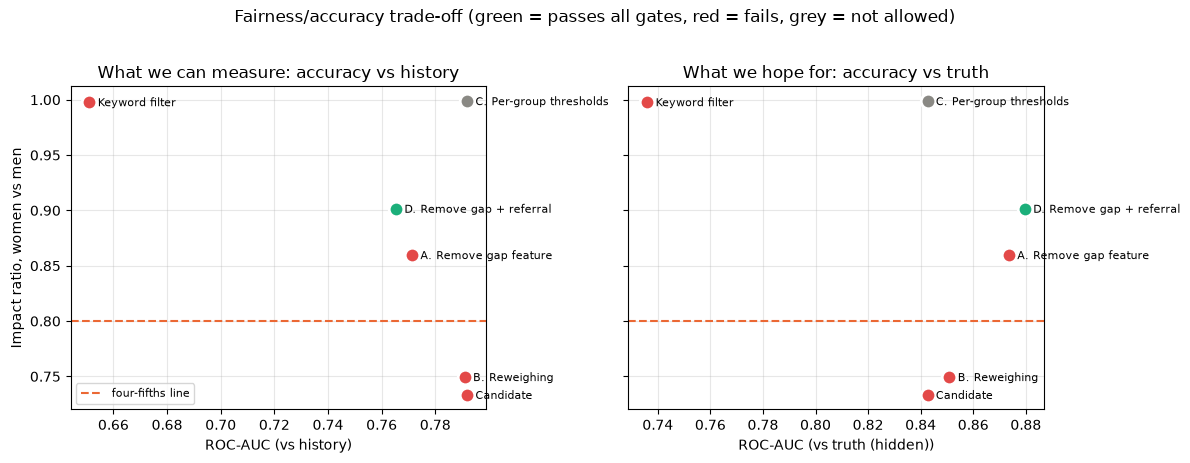

In [15]:
# Trade-off chart: usefulness (x) vs worst impact ratio by sex (y)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, auc_col in zip(axes, ["AUC vs history", "AUC vs truth (hidden)"]):
    for name, row in tradeoff.iterrows():
        color = COLORS["grey"] if not row["allowed_by_policy"] else (COLORS["aqua"] if row["passes_gates"] else COLORS["red"])
        ax.scatter(row[auc_col], row["min_impact_ratio_sex"], s=110, color=color, edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(name.split(" (")[0], (row[auc_col], row["min_impact_ratio_sex"]),
                    textcoords="offset points", xytext=(6, -3), fontsize=8)
    ax.axhline(POLICY.min_impact_ratio, color=COLORS["orange"], ls="--", label="four-fifths line")
    ax.set_xlabel(f"ROC-AUC ({auc_col.replace('AUC ', '')})"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Impact ratio, women vs men"); axes[0].legend(loc="lower left", fontsize=8)
axes[0].set_title("What we can measure: accuracy vs history"); axes[1].set_title("What we hope for: accuracy vs truth")
fig.suptitle("Fairness/accuracy trade-off (green = passes all gates, red = fails, grey = not allowed)", y=1.02)
plt.tight_layout(); plt.show()

**Reading the trade-off honestly** (numbers from the table above):
- **Reweighing alone (B) barely moves the impact ratio** (women: about 0.73 to 0.75, still a significant FAIL). The model never sees sex, so up-weighting women's examples cannot stop it from learning the *gap* penalty. A popular textbook fix is not automatically the right fix.
- **Removing the gap feature (A)** lifts women to about 0.86, but one intersection (women 40+) still fails significantly: the remaining proxy, `referral`, still favours men.
- **Removing both proxies (D)** passes every gate (worst intersection about 0.85). It costs about **0.03 AUC against the historical labels** (0.79 to 0.77).
- But against the **hidden truth**, the proxy-free models are *more* accurate (about 0.84 to 0.88): they were "losing" accuracy only at **reproducing past bias**. Real teams cannot see the truth column, so this argument needs evidence (blinded re-reviews of CVs, a job-relatedness analysis for each feature) and a written decision.
- **Per-group thresholds (C)** pass by construction, but are not allowed for hiring.
- Bonus finding: **today's keyword filter fails the age gate badly** (under-40s get far fewer shortlists, because keyword matches grow with experience). Reviews often expose problems in the *status quo*, not only in the new AI.

### The board's decision rule (written down **before** looking at test data)
High-risk use case, so **fairness first**: usefulness is already a gate (must beat the keyword filter), and among the options that are allowed by policy and pass all gates, the board picks the one with the **largest worst-group impact ratio** (sex × age). If none qualifies: **no launch**.

In [16]:
eligible = tradeoff[tradeoff["allowed_by_policy"] & tradeoff["passes_gates"]]
if eligible.empty:
    raise SystemExit("NO-GO: no option passes the Responsible-AI gates")      # stop the notebook loudly
chosen_name = eligible["min_impact_ratio_sex_x_age"].idxmax()     # fairness-first: largest worst-group margin
print(eligible[["AUC vs history", "min_impact_ratio_sex", "min_impact_ratio_age_band",
                "min_impact_ratio_sex_x_age"]].round(3))
chosen_model = options[chosen_name][0]
chosen_features = [c for c in FEATURES_NUM if c in chosen_model.named_steps["preprocess"].transformers[0][2]]
chosen_threshold = shortlist_threshold(options[chosen_name][1])       # cut-off fixed on VALIDATION scores
log.info("Chosen option: %s | features: %s | threshold %.3f", chosen_name, chosen_features, chosen_threshold)

2026-10-21 18:00:18,144 | INFO | Chosen option: D. Remove gap + referral | features: ['years_experience', 'skills_match', 'assessment_score', 'job_changes'] | threshold 0.251


                          AUC vs history  min_impact_ratio_sex  \
option                                                           
D. Remove gap + referral           0.765                 0.902   

                          min_impact_ratio_age_band  \
option                                                
D. Remove gap + referral                      0.941   

                          min_impact_ratio_sex_x_age  
option                                                
D. Remove gap + referral                       0.845  


---
## 10. Final audit on the untouched test period

Now, once, we apply the chosen model **and the validation threshold** to the second half of 2025, which played no role in any decision. This is the number that goes into the model card. (In a real NYC LL144 audit, an **independent auditor** would redo this step.)

In [17]:
test_scores = chosen_model.predict_proba(test)[:, 1]
test_selected = test_scores >= chosen_threshold
test_baseline = test["skills_match"].to_numpy()

final_metrics = {
    "test_rows": int(len(test)),
    "shortlist_rate": round(float(test_selected.mean()), 3),
    "auc_vs_history": round(roc_auc_score(test[POLICY.target], test_scores), 3),
    "keyword_auc_vs_history": round(roc_auc_score(test[POLICY.target], test_baseline), 3),
    **{k: (round(float(v), 3) if isinstance(v, float) else v) for k, v in audit_summary(test, test_selected).items()},
}
ir_low, ir_mid, ir_high = bootstrap_impact_ratio(test, test_selected, "sex", "Female", "Male")
final_metrics["impact_ratio_female_95ci"] = [round(ir_low, 3), round(ir_high, 3)]
print(json.dumps(final_metrics, indent=2))

final_tables = {a: fairness_table(with_intersection(test), test_selected, a)
                for a in POLICY.protected_attributes + ("sex_x_age",)}
for attribute, table in final_tables.items():
    print(f"\n=== Test period, chosen model, by {attribute} ===")
    print(show(table).to_string())

{
  "test_rows": 2654,
  "shortlist_rate": 0.308,
  "auc_vs_history": 0.76,
  "keyword_auc_vs_history": 0.672,
  "min_impact_ratio_sex": 0.976,
  "tpr_gap_sex": 0.071,
  "min_impact_ratio_age_band": 0.96,
  "tpr_gap_age_band": 0.055,
  "min_impact_ratio_sex_x_age": 0.912,
  "significant_IR_fails": 0,
  "significant_TPR_gap": false,
  "impact_ratio_female_95ci": [
    0.863,
    1.091
  ]
}

=== Test period, chosen model, by sex ===
                n  selection_rate    TPR    FPR  impact_ratio  p_value_vs_best              status
group                                                                                             
Female       1185           0.302  0.643  0.239         0.976            0.680                pass
Male         1379           0.310  0.573  0.217         1.000            1.000                pass
Undisclosed    90           0.356  0.850  0.214         1.148            0.363  too small: monitor

=== Test period, chosen model, by age_band ===
                n  se

**What the test period says:** the shortlist rate stays near 30% (31%; the threshold was fixed on validation, so a small deviation is normal), the model still beats the keyword filter (AUC 0.76 vs 0.67), every reliable group and intersection passes (worst impact ratio about 0.91), and the bootstrap interval for women vs men (about 0.86 to 1.09) lies entirely above 0.80.

One subtle number: women's TPR (about 0.64) is now *higher* than men's (0.57). That is what you expect when the labels were biased against women: women who got offers in the past had to be stronger, so a model that treats everyone the same shortlists more of them. The gap is within the 10-point limit, but it shows why TPR measured on biased labels must be interpreted, not just thresholded.

---
## 11. Human oversight: how the model is used

EU AI Act Art. 14 requires that people can **understand, override and stop** a high-risk system, and that the design fights **automation bias** (blindly following the AI). Product decisions that come out of this review:

1. The model **ranks**; it never rejects. Every application stays visible to the recruiter.
2. Each score comes with **reason codes** (which inputs pushed it up or down), so the recruiter can disagree.
3. A **borderline band** around the cut-off is flagged for careful human review.
4. Candidates can **request a human review** and an explanation (contestability).

Because the chosen model is a logistic regression, reason codes are simply *weight × standardized value* per feature.

In [18]:
def explain_application(model: Pipeline, application: pd.DataFrame, top_k: int = 3) -> dict:
    """Score + simple reason codes for ONE application (logistic regression contributions)."""
    pre, lr = model.named_steps["preprocess"], model.named_steps["model"]
    x = pre.transform(application)                                  # standardized numbers + one-hot education
    names = list(pre.get_feature_names_out())
    contributions = pd.Series(np.asarray(x).ravel() * lr.coef_[0], index=names)
    score = float(model.predict_proba(application)[0, 1])
    band = ("shortlist" if score >= chosen_threshold * 1.1 else
            "borderline: human review" if score >= chosen_threshold * 0.9 else "below cut-off: recruiter may still pick")
    return {"score": round(score, 3), "band": band,
            "pushes_up": contributions.nlargest(top_k).round(2).to_dict(),
            "pushes_down": contributions.nsmallest(top_k).round(2).to_dict()}


example = test.iloc[[int(np.argmin(np.abs(test_scores - chosen_threshold)))]]   # an applicant near the cut-off
print(example[["application_id"] + chosen_features + FEATURES_CAT].to_string(index=False))
print(json.dumps(explain_application(chosen_model, example), indent=2))

application_id  years_experience  skills_match  assessment_score  job_changes education
    A042-05473               1.4          72.0              59.0            0    Master


{
  "score": 0.251,
  "band": "borderline: human review",
  "pushes_up": {
    "num__skills_match": 0.22,
    "num__years_experience": 0.06,
    "cat__education_Master": 0.03
  },
  "pushes_down": {
    "num__assessment_score": -0.17,
    "num__job_changes": -0.03,
    "cat__education_Bachelor": -0.0
  }
}


---
## 12. Documentation generated from code: model card, risk register, launch checklist

Documents written by hand go stale. Mature teams **generate them from the same code and numbers** that produced the model, and store them next to the model version. We create three artifacts in a temporary folder (in a real project: `models/smart_shortlist/v1/` and the company's governance tool):

1. **Model card** (Mitchell et al., 2019): intended use, data, metrics *per group*, limitations.
2. **Risk register**: every risk with owner, mitigation, residual risk and status.
3. **Launch checklist**: automatic gates (computed) + manual sign-offs, ending in **GO / NO-GO**.

In [19]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="rai_review_"))      # real life: models/smart_shortlist/v1/


def df_to_markdown(df: pd.DataFrame) -> str:
    """Tiny markdown-table writer (avoids an extra dependency)."""
    header = "| " + " | ".join([df.index.name or ""] + list(df.columns)) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    body = ["| " + " | ".join([str(i)] + [f"{v:.3f}" if isinstance(v, float) else str(v) for v in row]) + " |"
            for i, row in zip(df.index, df.to_numpy())]
    return "\n".join([header, sep, *body])


group_sections = "\n\n".join(f"**By {a}**\n\n" + df_to_markdown(t[["n", "selection_rate", "impact_ratio", "TPR", "FPR", "status"]])
                             for a, t in final_tables.items())
model_card = f"""# Model card: Smart Shortlist v1.0.0
*Generated {date.today().isoformat()} from the review notebook. scikit-learn {sklearn.__version__}.*

## Intended use
Rank applications for recruiters at client companies. Recruiters interview roughly the top {POLICY.shortlist_rate:.0%}.
**Out of scope:** automatic rejection, promotion/termination decisions, roles the model was not validated on.

## Risk classification
{shortlist_risk['tier']} under the EU AI Act ({shortlist_risk['reason']}).

## Model
{chosen_name}: logistic regression on {', '.join(chosen_features + FEATURES_CAT)}.
Protected attributes ({', '.join(POLICY.protected_attributes)}) are not inputs; they are used only for auditing.

## Data
Applications {train['applied_at'].min():%Y-%m} to {train['applied_at'].max():%Y-%m} (training, {len(train):,} rows).
Validation {valid['applied_at'].min():%Y-%m} to {valid['applied_at'].max():%Y-%m}; test {test['applied_at'].min():%Y-%m} to {test['applied_at'].max():%Y-%m}.
Label = historical recruiter decision (known to contain bias against career gaps, women and 40+ applicants).

## Performance (test period)
ROC-AUC vs historical decisions: {final_metrics['auc_vs_history']} (keyword filter: {final_metrics['keyword_auc_vs_history']}).

## Fairness (test period)
{group_sections}

## Limitations and caveats
- Labels are past human decisions; accuracy vs the true job performance is unknown.
- The 'Undisclosed' sex group is too small to audit reliably; it is monitored instead.
- Not validated for roles outside the training job families; re-audit before expanding.
- Assessment-score imputation can disadvantage groups that skip the test (monitored).
"""
(ARTIFACT_DIR / "model_card.md").write_text(model_card)
print(model_card)

# Model card: Smart Shortlist v1.0.0
*Generated 2026-10-21 from the review notebook. scikit-learn 1.9.0.*

## Intended use
Rank applications for recruiters at client companies. Recruiters interview roughly the top 30%.
**Out of scope:** automatic rejection, promotion/termination decisions, roles the model was not validated on.

## Risk classification
HIGH RISK under the EU AI Act (Annex III area 'employment' + profiling of people).

## Model
D. Remove gap + referral: logistic regression on years_experience, skills_match, assessment_score, job_changes, education.
Protected attributes (sex, age_band) are not inputs; they are used only for auditing.

## Data
Applications 2023-01 to 2024-12 (training, 10,696 rows).
Validation 2025-01 to 2025-06; test 2025-07 to 2025-12.
Label = historical recruiter decision (known to contain bias against career gaps, women and 40+ applicants).

## Performance (test period)
ROC-AUC vs historical decisions: 0.76 (keyword filter: 0.672).

## Fairness (test pe

In [20]:
@dataclass
class Risk:
    """One line of the risk register."""
    risk_id: str
    description: str
    owner: str
    likelihood: int          # 1-5 BEFORE mitigation
    impact: int              # 1-5
    mitigation: str
    residual: str            # risk level AFTER mitigation: low / medium / high
    status: str = "open"


risk_register = pd.DataFrame([asdict(r) for r in [
    Risk("R1", "Proxy discrimination via career gaps", "ML lead", 4, 5,
         f"Chosen option '{chosen_name}'; impact-ratio gate in CI and monitoring", "low", "mitigated"),
    Risk("R2", "Historical labels encode recruiter bias", "Data science", 5, 4,
         "Blinded re-review of 300 CVs per quarter to estimate label bias", "medium", "in progress"),
    Risk("R3", "Recruiter automation bias", "Product", 4, 4,
         "Ranking only, reason codes, borderline band, training for recruiters", "medium", "mitigated"),
    Risk("R4", "Small 'Undisclosed' group cannot be audited", "Responsible-AI office", 4, 3,
         "Report counts; pool 12 months of data for the annual audit", "medium", "accepted"),
    Risk("R5", "Missing assessment scores more common for 40+", "ML lead", 3, 4,
         "Monitor missing rate per group; alert if gap > 10 points", "low", "monitoring"),
    Risk("R6", "Use outside validated roles", "Customer success", 3, 4,
         "Contractual scope in client instructions (Art. 13); per-role re-audit", "medium", "open"),
]])
risk_register["inherent_score"] = risk_register["likelihood"] * risk_register["impact"]
risk_register.to_csv(ARTIFACT_DIR / "risk_register.csv", index=False)
risk_register.sort_values("inherent_score", ascending=False)

,risk_id,description,owner,likelihood,impact,mitigation,residual,status,inherent_score
0,R1,Proxy discrimination via career gaps,ML lead,4,5,Chosen option 'D. Remove gap + referral'; impa...,low,mitigated,20
1,R2,Historical labels encode recruiter bias,Data science,5,4,Blinded re-review of 300 CVs per quarter to es...,medium,in progress,20
2,R3,Recruiter automation bias,Product,4,4,"Ranking only, reason codes, borderline band, t...",medium,mitigated,16
3,R4,Small 'Undisclosed' group cannot be audited,Responsible-AI office,4,3,Report counts; pool 12 months of data for the ...,medium,accepted,12
4,R5,Missing assessment scores more common for 40+,ML lead,3,4,Monitor missing rate per group; alert if gap >...,low,monitoring,12
5,R6,Use outside validated roles,Customer success,3,4,Contractual scope in client instructions (Art....,medium,open,12


In [21]:
def launch_checklist(metrics: dict, manual_signoffs: dict, policy: ReviewPolicy = POLICY) -> pd.DataFrame:
    """Automatic gates computed from metrics + manual sign-offs. Every item must be True to launch."""
    automatic = {
        "Beats keyword baseline (AUC)": metrics["auc_vs_history"] > metrics["keyword_auc_vs_history"],
        "No significant impact-ratio FAIL (sex, age, sex x age)": metrics["significant_IR_fails"] == 0,
        "No significant TPR gap above the limit": not metrics["significant_TPR_gap"],
        "Protected attributes not used as inputs": not set(policy.protected_attributes) & set(chosen_features),
        "Model card generated": (ARTIFACT_DIR / "model_card.md").exists(),
        "Risk register has no open HIGH residual risk": not ((risk_register["residual"] == "high")
                                                              & (risk_register["status"] == "open")).any(),
    }
    rows = [{"item": k, "type": "automatic", "passed": bool(v)} for k, v in automatic.items()]
    rows += [{"item": k, "type": "manual sign-off", "passed": bool(v)} for k, v in manual_signoffs.items()]
    return pd.DataFrame(rows)


signoffs = {   # in real life these come from a governance tool, with names and dates
    "Legal: risk tier & obligations reviewed": True,
    "HR/recruiter panel: oversight workflow tested": True,
    "Security & privacy review (data minimisation, retention)": True,
    "Candidate notice & contest process published": True,
}
checklist = launch_checklist(final_metrics, signoffs)
decision = "GO (limited pilot)" if checklist["passed"].all() else "NO-GO"
checklist.to_csv(ARTIFACT_DIR / "launch_checklist.csv", index=False)
print(checklist.to_string(index=False))
print(f"\nLaunch decision: {decision}")

                                                    item            type  passed
                            Beats keyword baseline (AUC)       automatic    True
  No significant impact-ratio FAIL (sex, age, sex x age)       automatic    True
                  No significant TPR gap above the limit       automatic    True
                 Protected attributes not used as inputs       automatic    True
                                    Model card generated       automatic    True
            Risk register has no open HIGH residual risk       automatic    True
                 Legal: risk tier & obligations reviewed manual sign-off    True
           HR/recruiter panel: oversight workflow tested manual sign-off    True
Security & privacy review (data minimisation, retention) manual sign-off    True
            Candidate notice & contest process published manual sign-off    True



Launch decision: GO (limited pilot)


Even with a "GO", responsible teams launch as a **limited pilot** (a few clients, extra monitoring) before a full rollout. If any automatic gate turns red after a code or data change, the same function returns NO-GO, which is why it can run in CI like any other test.

---
## 13. Monitoring plan, tested on simulated production months

Fairness is not a one-time certificate. Applicant pools change, clients change job ads, upstream systems change. The plan lists **what** we watch, **how often**, the **threshold**, the **owner** and the **action**.

In [22]:
monitoring_plan = pd.DataFrame([
    ("Impact ratio by sex and age (monthly cohorts)", "monthly", f"< {POLICY.min_impact_ratio}", "Responsible-AI office", "Investigate; pause for affected client if 2 months in a row"),
    ("Assessment-score missing rate per group", "weekly", "gap > 10 points", "Data engineering", "Fix upstream; re-audit"),
    ("Shortlist rate overall", "weekly", "outside 25-35%", "ML on-call", "Check threshold / data pipeline"),
    ("Recruiter override rate", "monthly", "< 5% (rubber-stamping) or > 40%", "Product", "Review training / model quality"),
    ("Candidate contest requests", "monthly", "any upheld complaint", "Legal", "Root-cause analysis"),
    ("Annual independent bias audit", "yearly", "required (NYC LL144)", "Legal", "Publish summary"),
], columns=["metric", "frequency", "alert_if", "owner", "action"])
monitoring_plan.to_csv(ARTIFACT_DIR / "monitoring_plan.csv", index=False)
monitoring_plan

,metric,frequency,alert_if,owner,action
0,Impact ratio by sex and age (monthly cohorts),monthly,< 0.8,Responsible-AI office,Investigate; pause for affected client if 2 mo...
1,Assessment-score missing rate per group,weekly,gap > 10 points,Data engineering,Fix upstream; re-audit
2,Shortlist rate overall,weekly,outside 25-35%,ML on-call,Check threshold / data pipeline
3,Recruiter override rate,monthly,< 5% (rubber-stamping) or > 40%,Product,Review training / model quality
4,Candidate contest requests,monthly,any upheld complaint,Legal,Root-cause analysis
5,Annual independent bias audit,yearly,required (NYC LL144),Legal,Publish summary


**Does the plan actually catch problems?** We simulate six production months in 2026. From month 4 a client switches to a new assessment vendor whose test is hard to access for many older applicants, so the share of 40+ applicants **without an assessment score** jumps. Nothing in the model changed, yet the pipeline may now disadvantage a group, because missing scores are filled with the median.

In [23]:
monthly = []
for month in range(1, 7):
    skip_rate = 0.15 if month < 4 else 0.60                     # month 4: new vendor, many 40+ skip the test
    batch = make_applications(n=3000, seed=100 + month, start=f"2026-{month:02d}-01",
                              end=f"2026-{month:02d}-28", skip_test_rate_40plus=skip_rate)
    selected = chosen_model.predict_proba(batch)[:, 1] >= chosen_threshold
    missing = batch.groupby("age_band")["assessment_score"].apply(lambda s: s.isna().mean())
    summary = audit_summary(batch, selected)
    monthly.append({"month": f"2026-{month:02d}", "shortlist_rate": selected.mean(),
                    "shortlist_rate_40plus": selected[(batch["age_band"] == "40 and over").to_numpy()].mean(),
                    "impact_ratio_sex": summary["min_impact_ratio_sex"],
                    "impact_ratio_age": summary["min_impact_ratio_age_band"],
                    "missing_gap_age_pts": (missing.max() - missing.min()) * 100})
monitor = pd.DataFrame(monthly).set_index("month")
monitor["alerts"] = [", ".join(a for a, hit in [
    ("IR sex", r.impact_ratio_sex < POLICY.min_impact_ratio), ("IR age", r.impact_ratio_age < POLICY.min_impact_ratio),
    ("missing-data gap", r.missing_gap_age_pts > 10), ("shortlist rate", not 0.25 <= r.shortlist_rate <= 0.35)] if hit)
    or "ok" for r in monitor.itertuples()]
monitor.round(3)

,shortlist_rate,shortlist_rate_40plus,impact_ratio_sex,impact_ratio_age,missing_gap_age_pts,alerts
month,,,,,,
2026-01,0.300,0.304,0.912,0.979,6.749,ok
2026-02,0.305,0.300,0.966,0.974,7.583,ok
2026-03,0.303,0.293,0.975,0.950,5.743,ok
2026-04,0.273,0.240,0.934,0.835,47.375,missing-data gap
2026-05,0.288,0.259,0.924,0.859,51.274,missing-data gap
2026-06,0.287,0.251,0.998,0.826,52.794,missing-data gap


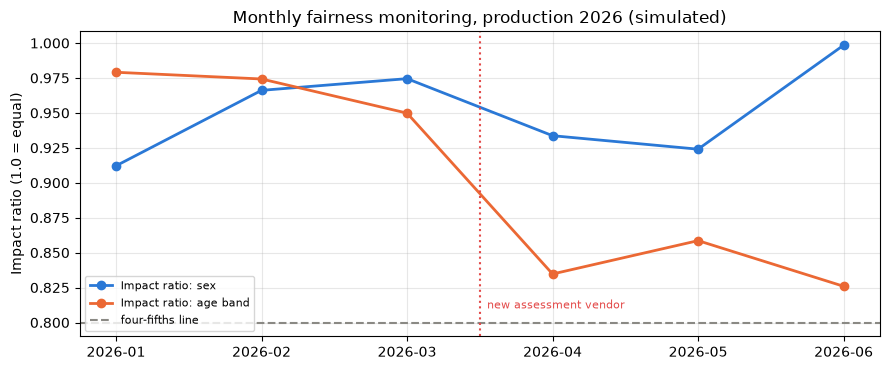

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(monitor))                                     # numeric positions; month names as tick labels
ax.plot(x, monitor["impact_ratio_sex"], marker="o", lw=2, color=COLORS["blue"], label="Impact ratio: sex")
ax.plot(x, monitor["impact_ratio_age"], marker="o", lw=2, color=COLORS["orange"], label="Impact ratio: age band")
ax.set_xticks(x, monitor.index)
ax.axhline(POLICY.min_impact_ratio, color=COLORS["grey"], ls="--", label="four-fifths line")
ax.axvline(2.5, color=COLORS["red"], ls=":", lw=1.5)
ax.text(2.55, ax.get_ylim()[0] + 0.02, "new assessment vendor", color=COLORS["red"], fontsize=8)
ax.set_ylabel("Impact ratio (1.0 = equal)"); ax.set_title("Monthly fairness monitoring, production 2026 (simulated)")
ax.legend(fontsize=8, loc="lower left"); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Read the `alerts` column: from month 4 the **missing-data gap** alert fires immediately (from about 6-8 to about 50 points). The 40+ shortlist rate falls from about 30% to about 25%, and the age impact ratio drops from about 0.95-0.98 to about 0.83-0.86, **still above 0.80**, so a monitor that only watched the impact ratio would have stayed silent. This is why the plan monitors **inputs per group**, not just the final fairness number: the input alert is earlier and points straight at the upstream cause. The fix (accessible test or a "missing" indicator with a re-audit) goes through the same review steps again.

---
## 14. Automated tests for the fairness tooling

Audit code is code, and a bug in it can hide discrimination. These small tests run in CI (normally with `pytest`; see `01_Python/04_industry_from_notebook_to_production_code.ipynb`).

In [25]:
def test_impact_ratio_matches_hand_calculation():
    """Example in the style of the NYC LL144 rules: 40/100 vs 50/100 selected -> impact ratio 0.8."""
    toy = pd.DataFrame({"sex": ["Female"] * 100 + ["Male"] * 100, POLICY.target: [1, 0] * 100})
    selected = np.array([1] * 40 + [0] * 60 + [1] * 50 + [0] * 50)
    table = fairness_table(toy, selected, "sex")
    assert abs(table.loc["Female", "impact_ratio"] - 0.8) < 1e-9
    assert table.loc["Male", "impact_ratio"] == 1.0


def test_gap_must_be_significant_to_fail():
    """30/100 vs 40/100 has impact ratio 0.75, but with 100 people per group that can be chance (p ~ 0.14)."""
    toy = pd.DataFrame({"sex": ["Female"] * 100 + ["Male"] * 100, POLICY.target: [1, 0] * 100})
    selected = np.array([1] * 30 + [0] * 70 + [1] * 40 + [0] * 60)
    assert fairness_table(toy, selected, "sex").loc["Female", "status"].startswith("warn")


def test_small_groups_are_not_passed_or_failed():
    toy = pd.DataFrame({"sex": ["Female"] * 100 + ["Undisclosed"] * 5, POLICY.target: [1] * 105})
    table = fairness_table(toy, np.ones(105), "sex")
    assert table.loc["Undisclosed", "status"] == "too small: monitor"


def test_reweighing_makes_group_and_label_independent():
    w = reweighing_weights(train, "sex")
    weighted = train.assign(w=w).groupby("sex").apply(lambda g: np.average(g[POLICY.target], weights=g["w"]))
    assert weighted.max() - weighted.min() < 1e-9           # same weighted offer rate in every group


def test_risk_classifier_blocks_emotion_recognition_at_work():
    assert classify_risk(portfolio[2])["tier"] == "PROHIBITED"
    assert classify_risk(portfolio[3])["tier"].startswith("NOT HIGH-RISK")


def test_model_card_has_required_sections():
    for section in ["## Intended use", "## Fairness", "## Limitations"]:
        assert section in model_card


for test_fn in [test_impact_ratio_matches_hand_calculation, test_gap_must_be_significant_to_fail,
                test_small_groups_are_not_passed_or_failed,
                test_reweighing_makes_group_and_label_independent,
                test_risk_classifier_blocks_emotion_recognition_at_work, test_model_card_has_required_sections]:
    test_fn()
    print(f"PASSED  {test_fn.__name__}")
print("\nArtifacts written to the temporary review folder:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

PASSED  test_impact_ratio_matches_hand_calculation
PASSED  test_gap_must_be_significant_to_fail
PASSED  test_small_groups_are_not_passed_or_failed
PASSED  test_reweighing_makes_group_and_label_independent
PASSED  test_risk_classifier_blocks_emotion_recognition_at_work
PASSED  test_model_card_has_required_sections

Artifacts written to the temporary review folder: ['launch_checklist.csv', 'model_card.md', 'monitoring_plan.csv', 'risk_register.csv']


---
## 15. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Intake + risk tier | `classify_risk()` with reasons and obligations | AI governance portals, EU AI Act compliance |
| Stakeholder & harm map | severity × likelihood table and matrix | NIST AI RMF "Map", Microsoft RAI Impact Assessment |
| Data review | representation, missingness, outcomes per group | EU AI Act Art. 10, datasheets for datasets |
| Baseline first | keyword filter vs model | Every review board asks "better than what we do today?" |
| Fairness audit | selection rate, impact ratio, TPR/FPR, small-group flags, bootstrap CI | NYC LL144 bias audits, EEOC four-fifths rule, Fairlearn `MetricFrame` |
| Root cause | proxy leakage AUC + model weights | Proxy-discrimination investigations |
| Mitigation comparison | feature removal, reweighing, per-group thresholds, policy check | Fairlearn / AIF360 mitigators, legal review |
| Human oversight | ranking only, reason codes, borderline band | EU AI Act Art. 14 |
| Generated docs | model card, risk register, GO/NO-GO checklist | Model registries, Google/Hugging Face model cards |
| Monitoring | per-group inputs + fairness metrics monthly, alerts | Post-market monitoring (Art. 72), MLOps dashboards |

**Key lessons**
1. A model can discriminate **without** seeing the protected attribute: proxies carry it.
2. "Accuracy" against biased historical labels partly measures **how well you copy past bias**.
3. Some mitigations that look perfect on paper (per-group thresholds) are **not allowed** in some domains. Check policy before maths.
4. Small groups need **uncertainty** and monitoring, not a pass/fail stamp.
5. Fairness is monitored like latency: continuously, per group, with owners and actions.

### Practice exercises
1. Change `min_impact_ratio` in `ReviewPolicy` to `0.90`. Which options still pass? What would the board do?
2. Reweigh by the intersection `sex + age_band` instead of `sex`. Does option B improve?
3. Add `HistGradientBoostingClassifier` as option E. Does the more complex model pass the gates? Is it still explainable enough for Section 11?
4. Fix the month-4 problem: add an `assessment_missing` indicator feature and re-run the monitoring loop. Does the age impact ratio recover?
5. Write a `datasheet` (Gebru et al.) for the training data in the same generated-from-code style as the model card.

### Resources (checked)
- EU AI Act, Regulation (EU) 2024/1689 (official text): https://eur-lex.europa.eu/eli/reg/2024/1689/oj
- EU AI Act Service Desk / explorer: https://artificialintelligenceact.eu/
- NIST AI Risk Management Framework: https://www.nist.gov/itl/ai-risk-management-framework
- NYC Local Law 144 (Automated Employment Decision Tools), DCWP: https://www.nyc.gov/site/dca/about/automated-employment-decision-tools.page
- EEOC Uniform Guidelines, four-fifths rule (29 CFR 1607.4): https://www.ecfr.gov/current/title-29/subtitle-B/chapter-XIV/part-1607
- Fairlearn (MetricFrame, mitigations, user guide): https://fairlearn.org/ and https://github.com/fairlearn/fairlearn
- AIF360 (includes the Reweighing algorithm): https://github.com/Trusted-AI/AIF360
- Kamiran & Calders (2012), *Data preprocessing techniques for classification without discrimination*: https://link.springer.com/article/10.1007/s10115-011-0463-8
- Mitchell et al. (2019), *Model Cards for Model Reporting*: https://arxiv.org/abs/1810.03993
- Gebru et al., *Datasheets for Datasets*: https://arxiv.org/abs/1803.09010
- Microsoft Responsible AI Impact Assessment template (PDF): https://blogs.microsoft.com/wp-content/uploads/prod/sites/5/2022/06/Microsoft-RAI-Impact-Assessment-Template.pdf
- Hugging Face model card guide: https://huggingface.co/docs/hub/model-cards

### Related notebooks in this repo
- `01_bias_and_fairness.ipynb`: the fairness metrics and the impossibility theorem in detail
- `02_transparency_and_explainability.ipynb`: SHAP, LIME and PDP from scratch
- `03_accountability_and_governance.ipynb`: EU AI Act, NIST RMF, model cards and audit logs
- `../03_Machine_Learning/07_explainability/03_industry_explaining_loan_decisions.ipynb`: explaining credit decisions to customers
- `../19_AI_Ethics_and_Safety/`: deeper ethics and safety material